**Week 10**<br />Friday, Nov. 6

# Machine Learning, Continued

LX 394/694<br />
Coding for Linguists

Sophie Hao


## Announcements

- Due to an error, HW 2 submissions will be accepted without penalty until Monday, Nov. 9, at 9 AM.
- HW 3 will be released **next week** on schedule.
- We are now on Chapter 5 of the textbook (Tagging).
- This is the first "real" computational linguistics topic we are covering.
- BUCLD is this week!

## Recap: Training and Evaluating Taggers

Which method of tagging is the best? We need to **evaluate** our taggers by comparing their performance on a **test set**.

In [2]:
import nltk
from nltk.corpus import brown

# Train–test split
dataset = brown.tagged_sents(categories="news")
n = int(len(dataset) * .8)
train_set = dataset[:n]
test_set = dataset[n:]

In [3]:
# Train some taggers
patterns = [
    (r'.*ing$', 'VBG'),                # gerunds
    (r'.*ed$', 'VBD'),                 # simple past
    (r'.*es$', 'VBZ'),                 # 3rd singular present
    (r'.*ould$', 'MD'),                # modals
    (r'.*\'s$', 'NN$'),                # possessive nouns
    (r'.*s$', 'NNS'),                  # plural nouns
    (r'^-?[0-9]+(\.[0-9]+)?$', 'CD'),  # cardinal numbers
    (r'.*', 'NN')                      # nouns (default)
]
regex = nltk.RegexpTagger(patterns)
unigram = nltk.UnigramTagger(train_set)
bigram = nltk.BigramTagger(train_set)
unigram_backoff = nltk.UnigramTagger(train_set, backoff=regex)
bigram_backoff = nltk.BigramTagger(train_set, backoff=unigram_backoff)

In [ ]:
# Evaluate
print(f"Regex Tagger:\t {regex.accuracy(test_set):.3f}")
print(f"Unigram Tagger:\t {unigram.accuracy(test_set):.3f}")
print(f"Bigram Tagger:\t {bigram.accuracy(test_set):.3f}\n")

print(f"Unigram Backoff: {unigram_backoff.accuracy(test_set):.3f}")
print(f"Bigram Backoff:\t {bigram_backoff.accuracy(test_set):.3f}\n")

## Recap: Baselines

When we create our own machine learning model, we need to compare it to **baseline models**. We usually want our model to be better than the baseline models in some way.

Baseline models usually include:
- the worst possible way of doing the task
- the current most typical way of doing the task
- the best possible way of doing the task

## Example: Olympic Ski Halfpipe Qualification Round

**Elizabeth Swaney** is an American, Venezuelan, Hungarian, and Israeli skier who represented Hungary at the 2018 Winter Olympics. She happens to be Sophie's favorite athlete.

Swaney is not a professional-level skier, but qualified for the Olympics mainly by [exploiting loopholes](https://en.wikipedia.org/wiki/Elizabeth_Swaney#Olympic_qualifying). She is therefore a natural baseline for measuring the performance of professional-level Olympic skiers.

| Rank | Score | Athlete | NOC |
|---|---|---|---|
| 1 | **93.40** | Cassie Sharpe | 🇨🇦 |
| 2 | 92.00 | Marie Martinod | 🇫🇷 |
| 3 | 90.60 | Brita Sigourney | 🇺🇸 |
| 4 | 86.00 | Annalisa Drew | 🇺🇸 |
| 5 | 84.80 | Ayana Onozuka | 🇯🇵 |
| … | … | … | … |
| 24 | 31.40 | Elizabeth Swaney | 🇭🇺 |

<a href="https://en.wikipedia.org/wiki/Freestyle_skiing_at_the_2018_Winter_Olympics_%E2%80%93_Women's_halfpipe" style="color: #cccccc">Source: Wikipedia</a>

## Random Baseline

The **random baseline** is a model that just guesses its output randomly (with uniform probability).

Note that we don't need to actually create the random baseline model in order to calculate its accuracy.

In [4]:
# Count how many tags there are in the training data
tagset = set()
for sent in train_set:
    _, tags = zip(*sent)
    tagset.add(tags)
len(tagset)

3571

In [5]:
# Random baseline accuracy
1 / len(tagset)

0.0002800336040324839

## Majority-Tag Baseline

The **majority-tag baseline** always guesses whatever is the most common tag in the training corpus.

In [6]:
# Find the most frequent tag in the training data
from nltk.probability import FreqDist

counts = FreqDist()
for sent in train_set:
    _, tags = zip(*sent)
    counts.update(tags)
counts.most_common(1)

[('NN', 10651)]

In [7]:
# How does the majority baseline do?
majority = nltk.DefaultTagger(counts.most_common(1)[0][0])
majority.accuracy(test_set)

0.1209595837949805

## Full Results

What can we conclude?

In [8]:
print(f"Random:\t\t {1 / len(tagset):.3f}")
print(f"Majority:\t {majority.accuracy(test_set):.3f}\n")
print(f"Regex Tagger:\t {regex.accuracy(test_set):.3f}")
print(f"Unigram Tagger:\t {unigram.accuracy(test_set):.3f}")
print(f"Bigram Tagger:\t {bigram.accuracy(test_set):.3f}\n")

print(f"Unigram Backoff: {unigram_backoff.accuracy(test_set):.3f}")
print(f"Bigram Backoff:\t {bigram_backoff.accuracy(test_set):.3f}\n")

Random:		 0.000
Majority:	 0.121

Regex Tagger:	 0.196
Unigram Tagger:	 0.803
Bigram Tagger:	 0.092

Unigram Backoff: 0.849
Bigram Backoff:	 0.858



## Language Modeling

**Language modeling** is an NLP task where, given a sequence of tokens $w_1, w_2, \dots, w_n$, the **language model** must predict the next token, $w_{n + 1}$.

Given input $w_1, w_2, \dots, w_n$, the language model's output is:

$$
\begin{Bmatrix}
   \text{the:} & \mathbb{P}[\text{the} | w_1, w_2, \dots, w_n] \\
   \text{of:} & \mathbb{P}[\text{of} | w_1, w_2, \dots, w_n] \\
   \text{in:} & \mathbb{P}[\text{in} | w_1, w_2, \dots, w_n] \\
   \vdots & \vdots
\end{Bmatrix}
$$


## Why Language Modeling?

We will learn about the following applications of language modeling:
- text generation
- classification (e.g., spam filtering)
- noisy channel model (e.g., spelling correction)

## Text Generation With a Language Model

You can generate text with a language model by repeatedly predicting next words.

Two common ways of generating text are...
- **Greedy generation:** always choose the token with the highest probability
- **Non-greedy generation:** choose a token based on the probability distribution from the language model

![The iPhone keyboard suggestions are generated by a language model.](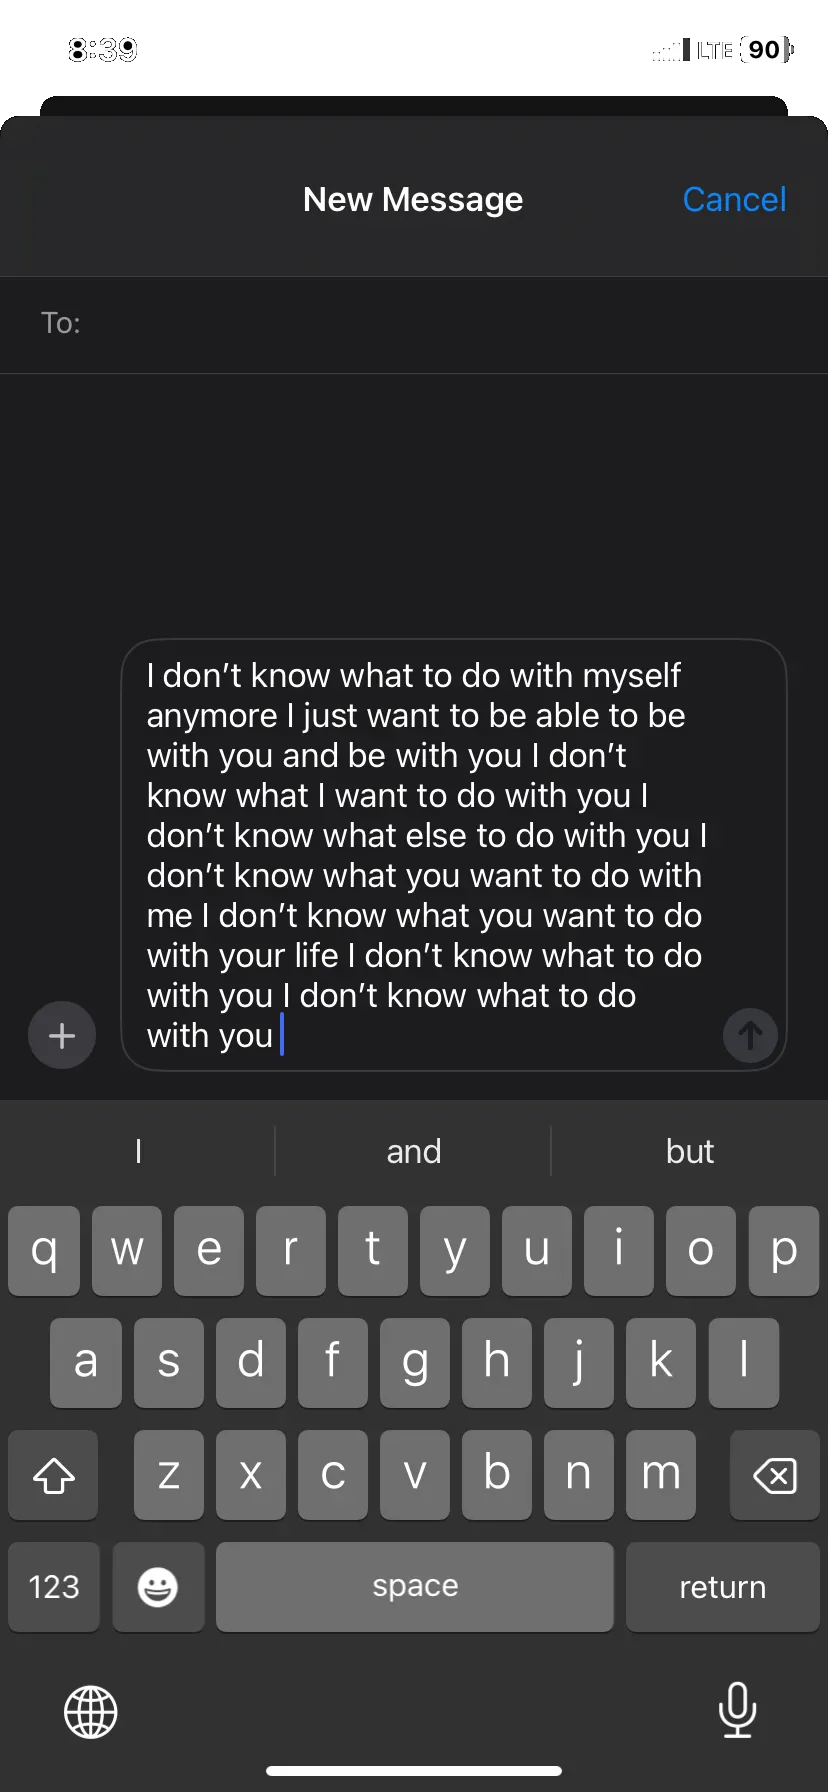 "The iPhone keyboard suggestions are generated by a language model.")

## Training a Language Model

Like unigram and bigram POS taggers, there are also unigram and bigram language models.

**Unigram Language Model:**
$$\mathbb{P}[w | w_1, w_2, \dots, w_n] = \mathbb{P}[w]$$

**Bigram Language Model:**
$$\mathbb{P}[w | w_1, w_2, \dots, w_n] = \mathbb{P}[w | w_n]$$

**Trigram Language Model:**
$$\mathbb{P}[w | w_1, w_2, \dots, w_n] = \mathbb{P}[w | w_n, w_{n - 1}]$$

## Language Modeling in NLTK

In [ ]:
from nltk.lm.preprocessing import padded_everygram_pipeline

text = [["Hello", "world", "!"],
        ["How", "are", "you", "?"]]
train, vocab = padded_everygram_pipeline(2, text)

print(set(vocab))
list(tuple(t) for t in train)

## Training Unigram and Bigram Models

In [ ]:
from nltk.corpus import brown

train, vocab = padded_everygram_pipeline(3, brown.sents(categories="news"))

In [ ]:
from nltk.lm import MLE

lm = MLE(3)
lm.fit(train, vocab)

In [ ]:
lm.generate(10)

## Smoothing and Backoff

How do smoothing and backoff work for $n$-gram language models?

Why are they necessary?

## Next Time

Language Modeling